In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train =pd.read_csv("train-test.csv")

In [3]:
train.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [4]:
train.shape

(48000, 14)

In [5]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [6]:
print("Dataset loaded successfully")
print("Shape:", train.shape)
print("Rows:", train.shape[0])
print("Columns:", train.shape[1])

Dataset loaded successfully
Shape: (48000, 14)
Rows: 48000
Columns: 14


In [7]:
print("Columns:")
print(train.columns.tolist())

Columns:
['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal', 'posted_rate']


In [8]:
train.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB


In [9]:
display(train.describe().T)


,count,mean,std,min,25%,50%,75%,max
pickup_lat,48000.0,35.647545,4.315285,28.35765,31.98691,35.29479,39.411040,44.30296
pickup_lon,48000.0,-90.928964,13.482431,-121.69849,-98.40059,-88.08915,-83.285060,-69.50000
delivery_lat,48000.0,35.641175,4.317199,28.35765,31.98691,35.29479,39.411040,44.30296
delivery_lon,48000.0,-90.857310,13.476589,-121.69849,-98.40059,-87.52871,-83.285060,-69.50000
distance,48000.0,1135.856654,728.564416,70.00000,550.40000,953.30000,1645.525000,3439.80000
weight,47700.0,31028.844004,9391.440620,-47500.00000,25800.00000,31436.50000,37018.000000,47500.00000
market_index,47626.0,1.083387,0.168091,0.67639,0.94967,1.05580,1.219590,1.46778
quote_signal,48000.0,2.062468,0.291391,0.69228,1.89103,2.05575,2.221685,3.61035
posted_rate,48000.0,2373.980682,1486.493245,57.22000,1251.55500,2030.76000,3330.750000,25533.00000


In [10]:
display(train.describe(include="object").T)


,count,unique,top,freq
load_id,48000,48000,TR-000001,1
pickup,48000,64,Oklahoma City,1242
delivery,48000,64,Lexington,1197
equipment,48000,3,Dry Van,27202
date,48000,304,2025-06-17,198


In [11]:
# Missing values
missing = pd.DataFrame({
    "Missing Count": train.isnull().sum(),
    "Missing Percentage": train.isnull().mean() * 100
}).sort_values("Missing Percentage", ascending=False)

display(missing)

,Missing Count,Missing Percentage
market_index,374,0.779167
weight,300,0.625000
load_id,0,0.000000
pickup,0,0.000000
delivery,0,0.000000
pickup_lat,0,0.000000
pickup_lon,0,0.000000
delivery_lat,0,0.000000
delivery_lon,0,0.000000
distance,0,0.000000


In [12]:
print("Duplicate rows:", train.duplicated().sum())


Duplicate rows: 0


In [13]:
# Unique values per column
print("\nUnique values:")
display(train.nunique().to_frame("Unique Values"))


Unique values:


,Unique Values
load_id,48000
pickup,64
delivery,64
pickup_lat,64
pickup_lon,63
delivery_lat,64
delivery_lon,63
distance,21204
equipment,3
weight,23678


In [14]:
train["date"] = pd.to_datetime(train["date"], errors="coerce")


In [15]:
# Check invalid numeric values
numeric_cols = [
    "pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon",
    "distance", "weight", "market_index", "quote_signal", "posted_rate"
]

for col in numeric_cols:
    train[col] = pd.to_numeric(train[col], errors="coerce")

print("Date range:", train["date"].min(), "to", train["date"].max())


Date range: 2025-01-01 00:00:00 to 2025-10-31 00:00:00


In [16]:
numeric_cols

['pickup_lat',
 'pickup_lon',
 'delivery_lat',
 'delivery_lon',
 'distance',
 'weight',
 'market_index',
 'quote_signal',
 'posted_rate']

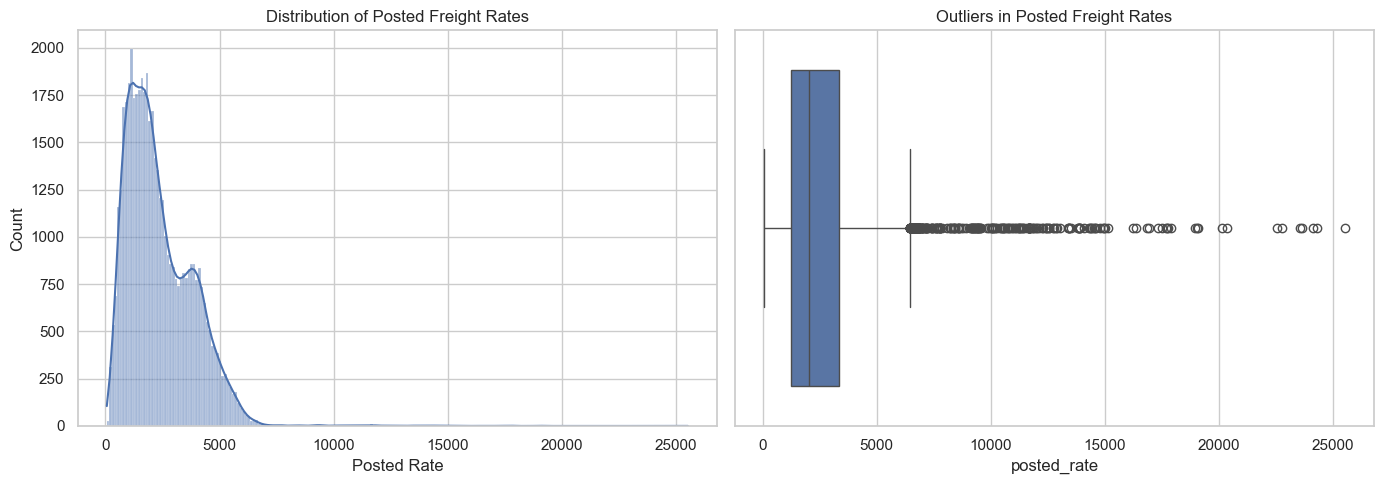

In [17]:

# Distribution of the target variable
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(train["posted_rate"].dropna(), kde=True, ax=axes[0])
axes[0].set_title("Distribution of Posted Freight Rates")
axes[0].set_xlabel("Posted Rate")

sns.boxplot(x=train["posted_rate"], ax=axes[1])
axes[1].set_title("Outliers in Posted Freight Rates")

plt.tight_layout()
plt.show()


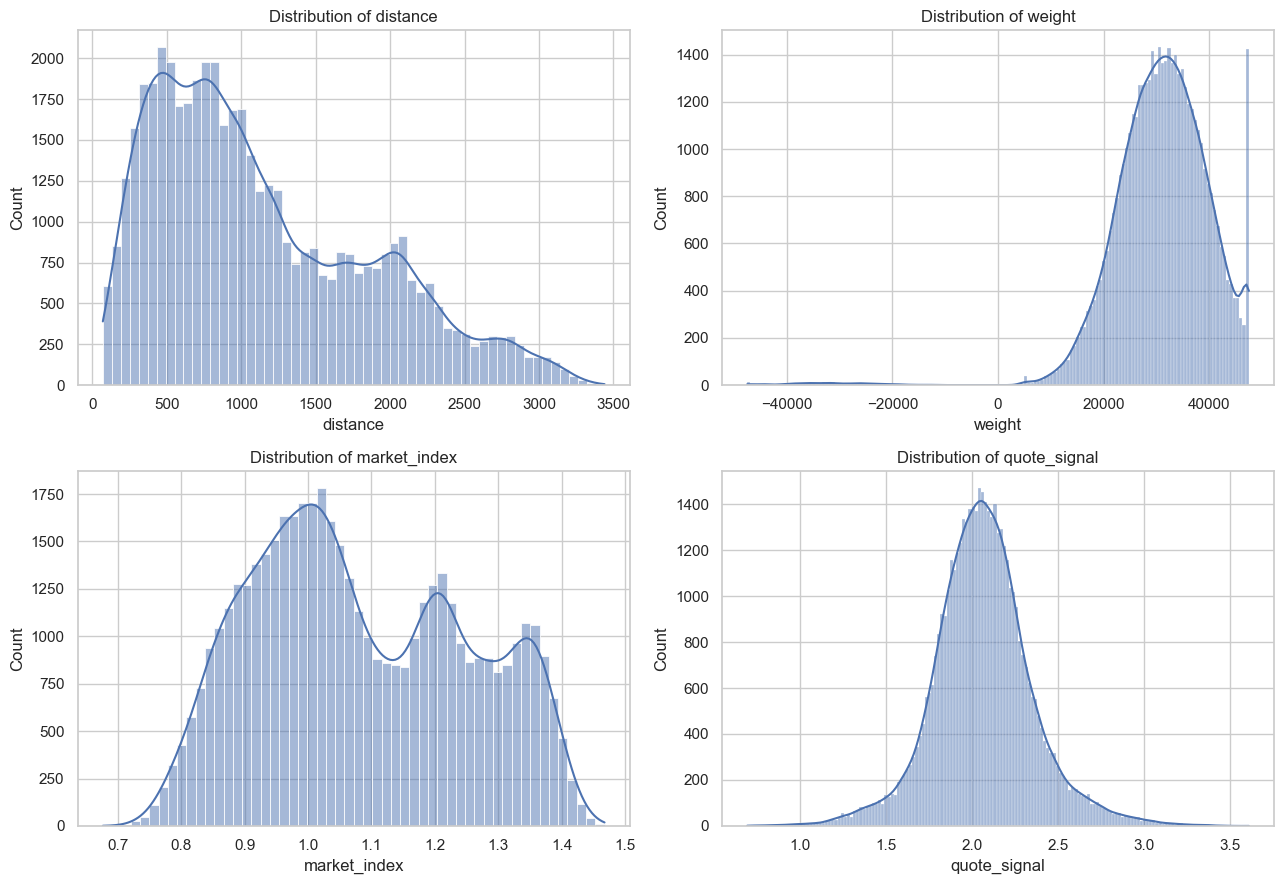

In [18]:

# Distributions of numerical features
features = ["distance", "weight", "market_index", "quote_signal"]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for col, ax in zip(features, axes.flatten()):
    sns.histplot(data=train, x=col, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()


In [19]:

categorical_cols = ["pickup", "delivery", "equipment"]

for col in categorical_cols:
    print(f"\nTop 10 values in {col}:")
    display(train[col].value_counts().head(10).to_frame("Shipment Count"))



Top 10 values in pickup:


,Shipment Count
pickup,
Oklahoma City,1242
Lexington,1209
Bakersfield,1193
Fort Wayne,1170
Hartford,1150
Richmond,1140
Nashville,1124
Phoenix,1121
Baton Rouge,1115



Top 10 values in delivery:


,Shipment Count
delivery,
Lexington,1197
Fort Wayne,1176
Baton Rouge,1167
Bakersfield,1156
Hartford,1143
Oklahoma City,1140
Richmond,1109
Atlanta,1096
Phoenix,1090



Top 10 values in equipment:


,Shipment Count
equipment,
Dry Van,27202
Reefer,12045
Flatbed,8753


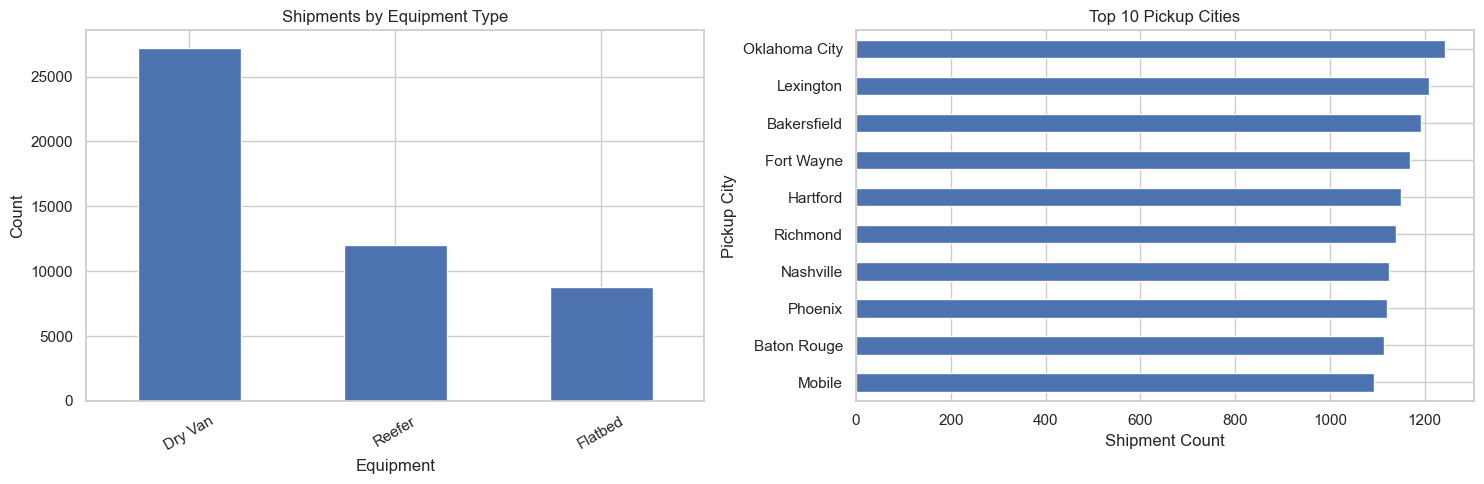

In [20]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

train["equipment"].value_counts().plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Shipments by Equipment Type")
axes[0].set_xlabel("Equipment")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=30)

train["pickup"].value_counts().head(10).sort_values().plot(
    kind="barh", ax=axes[1]
)
axes[1].set_title("Top 10 Pickup Cities")
axes[1].set_xlabel("Shipment Count")
axes[1].set_ylabel("Pickup City")

plt.tight_layout()
plt.show()


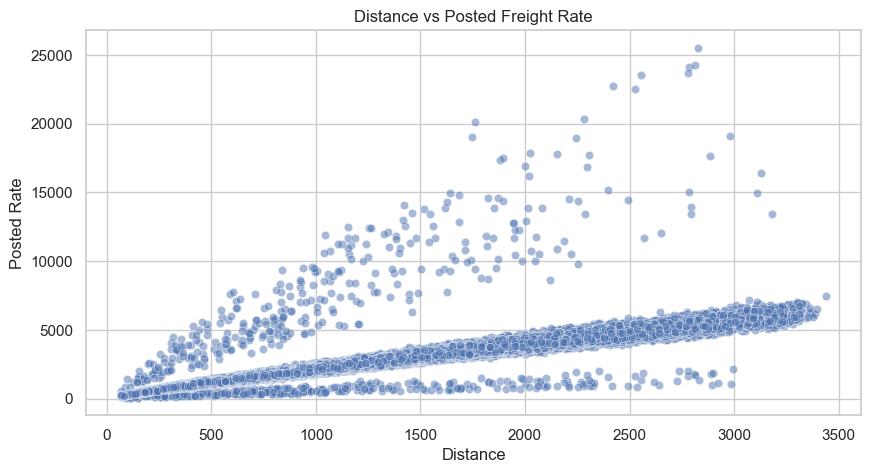

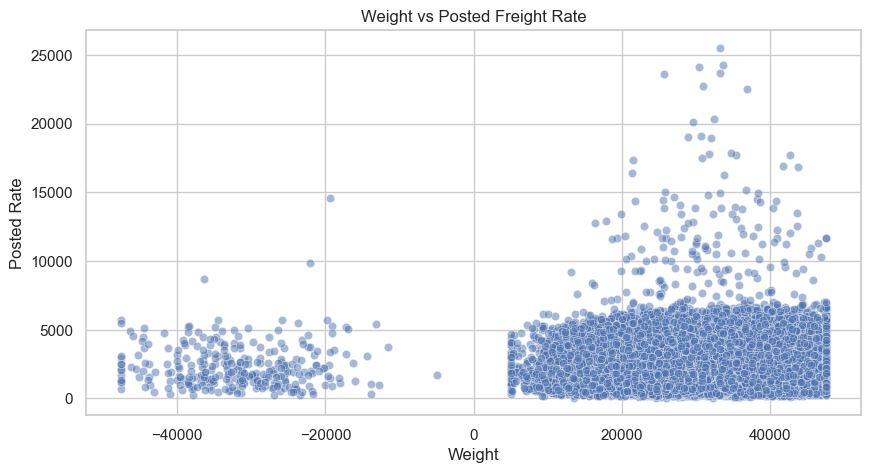

In [21]:

# Distance versus posted rate
sns.scatterplot(
    data=train,
    x="distance",
    y="posted_rate",
    alpha=0.5
)
plt.title("Distance vs Posted Freight Rate")
plt.xlabel("Distance")
plt.ylabel("Posted Rate")
plt.show()

# Weight versus posted rate
sns.scatterplot(
    data=train,
    x="weight",
    y="posted_rate",
    alpha=0.5
)
plt.title("Weight vs Posted Freight Rate")
plt.xlabel("Weight")
plt.ylabel("Posted Rate")
plt.show()


## Apply machine-learning regression algorithms to predict `posted_rate` (the freight price)

In [23]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Start with a copy of your dataset
data = train.copy()

# Convert date into numerical calendar features
data["date"] = pd.to_datetime(data["date"], errors="coerce")
data["year"] = data["date"].dt.year
data["month"] = data["date"].dt.month
data["day"] = data["date"].dt.day
data["day_of_week"] = data["date"].dt.dayofweek
data = data.drop(columns=["date", "load_id"], errors="ignore")

# Ensure target is numeric and remove rows without target
data["posted_rate"] = pd.to_numeric(
    data["posted_rate"], errors="coerce"
)
data = data.dropna(subset=["posted_rate"])

# Separate input features and target
X = data.drop(columns=["posted_rate"])
y = data["posted_rate"]


In [24]:
data

,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,market_index,quote_signal,posted_rate,year,month,day,day_of_week
0,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,0.95684,2.39595,645.41,2025,1,1,2
1,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,0.97623,2.43355,679.97,2025,1,1,2
2,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,1.00971,1.84491,1802.54,2025,1,1,2
3,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,0.94518,1.87712,1827.28,2025,1,1,2
4,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,0.98480,2.56300,1380.28,2025,1,1,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47995,Reno,Baton Rouge,39.54838,-118.64843,30.50134,-92.65374,1830.9,Flatbed,31786.0,0.98865,2.05626,3787.32,2025,10,31,4
47996,Greensboro,Memphis,35.98195,-82.78379,35.56802,-89.52871,445.8,Reefer,37465.0,1.03034,1.51985,1171.93,2025,10,31,4
47997,Greensboro,Cincinnati,35.98195,-82.78379,37.15706,-86.77499,267.9,Flatbed,24528.0,1.00846,1.46954,713.36,2025,10,31,4
47998,Memphis,Reno,35.56802,-89.52871,39.54838,-118.64843,1901.3,Flatbed,37581.0,1.00014,2.05132,3987.46,2025,10,31,4


In [25]:
# Identify categorical and numerical features
categorical_cols = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()


In [26]:
categorical_cols

['pickup', 'delivery', 'equipment']

In [27]:
print("Dataset shape:", data.shape)


Dataset shape: (48000, 16)


In [28]:
print("Numerical features:", numerical_cols)


Numerical features: ['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'weight', 'market_index', 'quote_signal', 'year', 'month', 'day', 'day_of_week']


In [29]:
print("Categorical features:", categorical_cols)


Categorical features: ['pickup', 'delivery', 'equipment']


In [30]:
print("Target: posted_rate")


Target: posted_rate


In [32]:

if data["year"].nunique() > 1 or (
    "month" in data.columns and data["month"].nunique() > 1
):
    # Chronological split based on the original date
    original_dates = pd.to_datetime(
        train.loc[data.index, "date"], errors="coerce"
    )
    order = original_dates.sort_values(
        kind="stable"
    ).index

    split_idx = int(len(order) * 0.80)
    train_idx = order[:split_idx]
    test_idx = order[split_idx:]

    X_train, X_test = X.loc[train_idx], X.loc[test_idx]
    y_train, y_test = y.loc[train_idx], y.loc[test_idx]
else:
    # Fallback when the dataset contains only one date
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )


In [33]:
split_idx

38400

In [34]:
train_idx

Index([    0,     1,     2,     3,     4,     5,     6,     7,     8,     9,
       ...
       38390, 38391, 38392, 38393, 38394, 38395, 38396, 38397, 38398, 38399],
      dtype='int64', length=38400)

In [35]:
test_idx

Index([38400, 38401, 38402, 38403, 38404, 38405, 38406, 38407, 38408, 38409,
       ...
       47990, 47991, 47992, 47993, 47994, 47995, 47996, 47997, 47998, 47999],
      dtype='int64', length=9600)

In [36]:
print("Training samples:", len(X_train))

Training samples: 38400


In [37]:
print("Testing samples:", len(X_test))


Testing samples: 9600


In [38]:
## Preprocess the data
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])


In [39]:
preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median'))]),
                                 ['pickup_lat', 'pickup_lon', 'delivery_lat',
                                  'delivery_lon', 'distance', 'weight',
                                  'market_index', 'quote_signal', 'year',
                                  'month', 'day', 'day_of_week']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['pickup', 'delivery', 'equipment'])])

In [44]:
## Train five ML algorithms

In [40]:

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=20,
        min_samples_leaf=5,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Algorithm": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = pipeline

    print(f"{name} completed")


Linear Regression completed
Decision Tree completed
Random Forest completed
Extra Trees completed
Gradient Boosting completed


In [41]:
## Compare model performance
results_df = pd.DataFrame(results).sort_values(
    by="RMSE", ascending=True
).reset_index(drop=True)

display(results_df.round(4))

best_model_name = results_df.iloc[0]["Algorithm"]
best_model = trained_models[best_model_name]

print("Best model by RMSE:", best_model_name)


,Algorithm,MAE,RMSE,R2 Score
0,Gradient Boosting,130.2385,636.4553,0.8258
1,Linear Regression,146.6939,637.4668,0.8253
2,Random Forest,144.0047,648.6725,0.8191
3,Extra Trees,153.0252,669.6227,0.8072
4,Decision Tree,166.8346,678.9316,0.8018


Best model by RMSE: Gradient Boosting


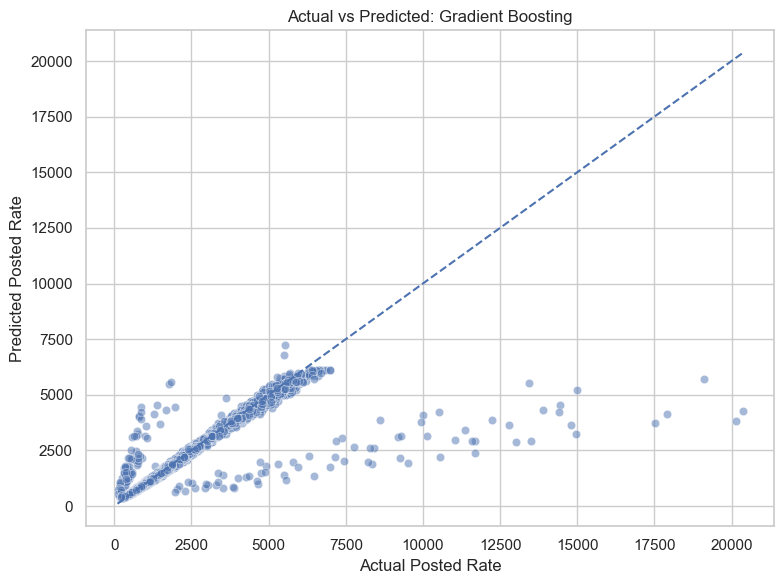

In [42]:
## Visualize actual versus predicted rates
import matplotlib.pyplot as plt
import seaborn as sns

best_predictions = best_model.predict(X_test)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=y_test,
    y=best_predictions,
    alpha=0.5
)

min_val = min(y_test.min(), best_predictions.min())
max_val = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual Posted Rate")
plt.ylabel("Predicted Posted Rate")
plt.title(f"Actual vs Predicted: {best_model_name}")
plt.tight_layout()
plt.show()


,Feature,Importance
4,num__distance,0.978719
140,cat__equipment_Dry Van,0.008005
5,num__weight,0.004377
6,num__market_index,0.003313
142,cat__equipment_Reefer,0.002247
9,num__month,0.001308
7,num__quote_signal,0.000846
82,cat__delivery_Baltimore,0.000472
0,num__pickup_lat,0.000309
2,num__delivery_lat,0.000129


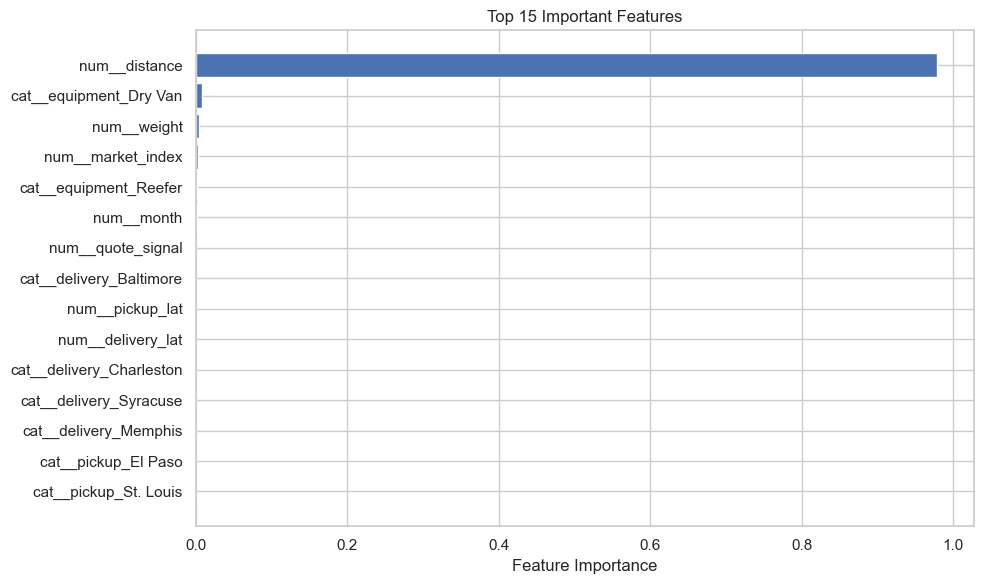

In [43]:
# Analyze feature importance
if best_model_name in [
    "Decision Tree", "Random Forest",
    "Extra Trees", "Gradient Boosting"
]:
    fitted_preprocessor = best_model.named_steps["preprocessor"]
    fitted_model = best_model.named_steps["model"]

    feature_names = fitted_preprocessor.get_feature_names_out()

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": fitted_model.feature_importances_
    }).sort_values("Importance", ascending=False)

    display(importance_df.head(15))

    top_features = importance_df.head(15).sort_values("Importance")

    plt.figure(figsize=(10, 6))
    plt.barh(top_features["Feature"], top_features["Importance"])
    plt.title("Top 15 Important Features")
    plt.xlabel("Feature Importance")
    plt.tight_layout()
    plt.show()
else:
    print("The selected model does not expose tree-based feature importance.")
